<a href="https://colab.research.google.com/github/simsekergun/ENEE684/blob/main/Tidy3D_LiN_AV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analysis of dielectric waveguides with Tidy3D

In [ ]:
#  !pip install tidy3d

In [ ]:
import sys
print(sys.executable)

c:\Users\abvos\Desktop\PhotonicsHW\.venv\Scripts\python.exe


In [ ]:
# standard python imports
import numpy as np
import matplotlib.pylab as plt

# tidy3D import
import tidy3d as td
from tidy3d.constants import C_0
import tidy3d.web as web
from tidy3d.plugins.mode import ModeSolver

# Paper Figure 3 - Z-cut TFLN


11:31:04 Eastern Daylight Time WARNING: The simulation has zero size along the x
                               axis, so using a PML or absorbing boundary along 
                               that axis is incorrect. Use either 'Periodic' or 
                               'BlochBoundary' along x. Using 'Periodic'        
                               boundary by default.                             

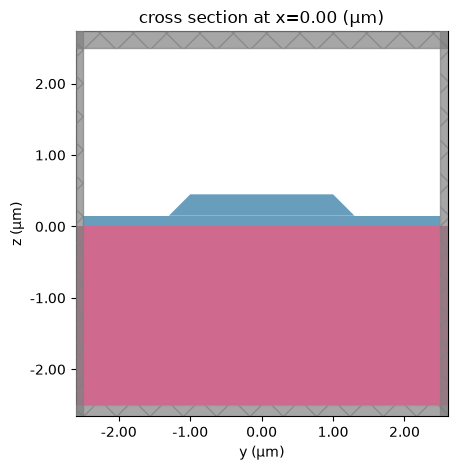

In [ ]:
# size of simulation domain
Lx, Ly, Lz = 0, 5, 5
dl = 0.05

# waveguide information
wg_width_bottom = 2.6
wg_width_top = 2.0
wg_height = 0.3
film_height = 0.15

px1 = -wg_width_bottom/2
py1 = film_height
px2 = -wg_width_top/2
py2 = wg_height + film_height
px3 = wg_width_top/2
py3 = wg_height + film_height
px4 = wg_width_bottom/2
py4 = film_height

vertices = np.array([(px1,py1), (px2,py2), (px3,py3), (px4, py4)])
tapered_wg = td.PolySlab(vertices=vertices, axis=0, slab_bounds=(-1, 1))

SiO2 = td.material_library["SiO2"]["Palik_LowLoss"]
LiNbO3 = td.material_library["LiNbO3"]["Zelmon1997"](2)

wg_permittivity = 2.1**2
film_permittivity = wg_permittivity
substrate_permittivity = 1.6**2
bg_permittivity = 1.0**2

# central frequency
wvl_um = 1.55
freq0 = C_0 / wvl_um
fwidth = freq0 / 3

# run_time in ps
run_time = 1e-12

# automatic grid specification
grid_spec = td.GridSpec.auto(min_steps_per_wvl=80, wavelength=wvl_um)

waveguide = td.Structure(
    geometry=tapered_wg,
    medium=LiNbO3,
)

film = td.Structure(
    geometry=td.Box(size=(td.inf, Ly, film_height),
                    center=[0, 0, film_height/2]),
    medium=LiNbO3,
)

substrate = td.Structure(
    geometry=td.Box(size=(td.inf, td.inf, Lz/2),
                    center=[0, 0, -Lz/4]),
    medium=SiO2,
)


sim = td.Simulation(
    size=(Lx, Ly, Lz),
    grid_spec=grid_spec,
    medium=td.Medium(permittivity=bg_permittivity),
    structures=[waveguide, film, substrate],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(y=td.Boundary.pml(), z=td.Boundary.pml()),
)

ax = sim.plot(x=0)
plt.show()



## Fig 3a and c-1 - TM0, TE2 @ 1550nm

In [ ]:
# wavelength sweep (1.4um to 1.7um)

plane = td.Box(center=(0, 0, 0), size=(0, 4, 3.0))

wavelengths = np.linspace(1.4, 1.7, 21)
freqs = td.C_0 / wavelengths

mode_spec = td.ModeSpec(
    num_modes=4,
    target_neff=1.9,
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=plane,
    mode_spec=mode_spec,
    freqs=freqs
)

mode_data = mode_solver.solve()
mode_data.to_dataframe()



wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
2.141375e+14 0                1.400  1.964449    0.0           0.0   
             1                1.400  1.903013    0.0           0.0   
             2                1.400  1.803495    0.0           0.0   
             3                1.400  1.758506    0.0           0.0   
2.118675e+14 0                1.415  1.960270    0.0           0.0   
...                             ...       ...    ...           ...   
1.779184e+14 3                1.685  1.638475    0.0           0.0   
1.763485e+14 0                1.700  1.882402    0.0           0.0   
             1                1.700  1.792451    0.0           0.0   
             2                1.700  1.654603    0.0           0.0   
             3                1.700  1.632679    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
2.141375e+14 0                   0.999017        0.980758        0.871509   
             1                   0.994432        0.926782        0.875946   
             2                   0.970456        0.853911        0.881882   
             3                   0.018583        0.759102        0.980127   
2.118675e+14 0                   0.998991        0.980329        0.870337   
...                                   ...             ...             ...   
1.779184e+14 3                   0.020347        0.755087        0.972079   
1.763485e+14 0                   0.998420        0.971456        0.851017   
             1                   0.989787        0.895628        0.859277   
             2                   0.931239        0.822966        0.870219   
             3                   0.020442        0.756041        0.971638   

                         mode area  
f            mode_index             
2.141375e+14 0            0.882674  
             1            1.002932  
             2            1.210134  
             3            1.380915  
2.118675e+14 0            0.890130  
...                            ...  
1.779184e+14 3            1.803227  
1.763485e+14 0            1.051776  
             1            1.287656  
             2            1.759417  
             3            1.828016  

[84 rows x 8 columns]

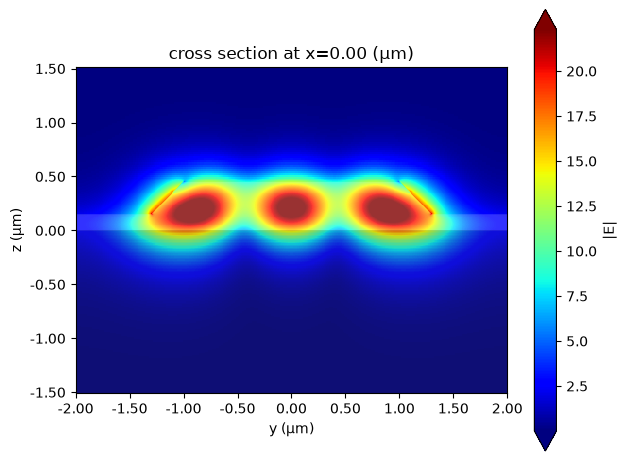

In [ ]:
# Plot modes of E field to find their specific modes
mode_index = 2

freq0 = C_0 / 1.55
mode_solver.plot_field("E", val="abs", mode_index=mode_index, f=freq0, cmap='jet')
plt.show()

# mode 3 = TM0
# mode 2 = TE2



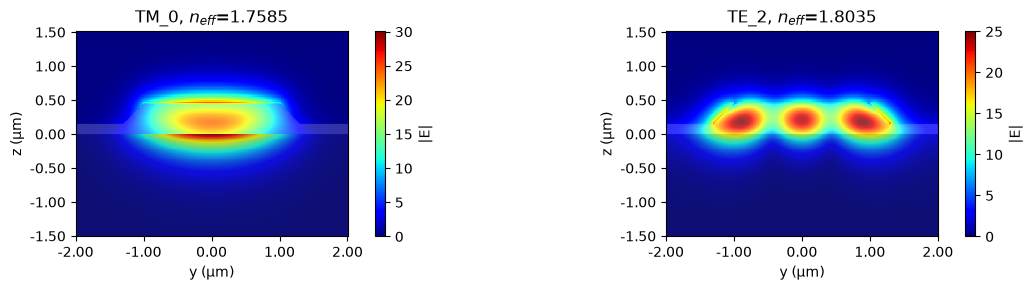

In [ ]:

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(12, 3))
freq0 = C_0 / 1.55

# TM0
neff = np.real(mode_data.n_eff.isel(f=0, mode_index=3).values)
mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=3,
        f=freq0,
        ax=ax1,
        robust=False,
        cmap="jet"
    )

ax1.set_title(f"TM_0, $n_{{eff}}$={neff:.4f}")

# TE2
neff = np.real(mode_data.n_eff.isel(f=0, mode_index=2).values)
mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=2,
        f=freq0,
        ax=ax2,
        robust=False,
        cmap="jet"
    )

ax2.set_title(f"TE_2, $n_{{eff}}$={neff:.4f}")

plt.tight_layout()
plt.show()

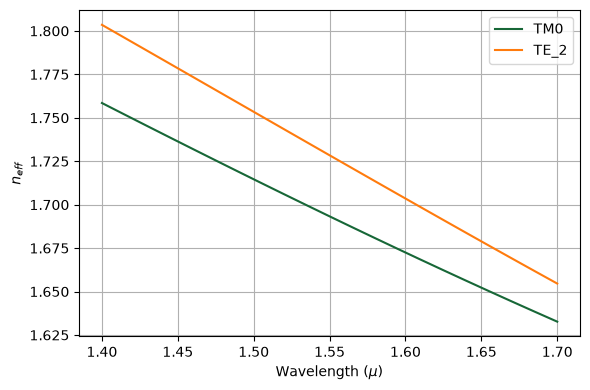

In [ ]:
n_eff = mode_data.n_eff.values

label = ['TM0', 'TE_2']

fig, ax = plt.subplots(1, 1, figsize=(6, 4), tight_layout=True)
ax.plot(wavelengths, n_eff[:, 3], label=label[0])
ax.plot(wavelengths, n_eff[:, 2], label=label[1])

ax.set_xlabel(r"Wavelength ($\mu$)")
ax.set_ylabel("$n_{eff}$")
ax.legend()
plt.grid()
plt.show()

## Fig 3b and c-2 - TE0, TE1, TE2, TM0 @ 775nm

In [ ]:
# wavelength sweep (0.6um to 0.9um)


# central frequency
wvl_um = 0.775
freq0 = C_0 / wvl_um
fwidth = freq0 / 3


# automatic grid specification
grid_spec = td.GridSpec.auto(min_steps_per_wvl=80, wavelength=wvl_um)

sim = td.Simulation(
    size=(Lx, Ly, Lz),
    grid_spec=grid_spec,
    medium=td.Medium(permittivity=bg_permittivity),
    structures=[waveguide, film, substrate],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(y=td.Boundary.pml(), z=td.Boundary.pml()),
)



wavelengths = np.linspace(0.6, 0.9, 21)
freqs = td.C_0 / wavelengths

mode_spec = td.ModeSpec(
    num_modes=6,
    target_neff=2.3,
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=plane,
    mode_spec=mode_spec,
    freqs=freqs
)

mode_data = mode_solver.solve()
mode_data.to_dataframe()

11:32:26 Eastern Daylight Time WARNING: The simulation has zero size along the x
                               axis, so using a PML or absorbing boundary along 
                               that axis is incorrect. Use either 'Periodic' or 
                               'BlochBoundary' along x. Using 'Periodic'        
                               boundary by default.                             

wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
4.996541e+14 0                  0.6  2.226088    0.0           0.0   
             1                  0.6  2.215280    0.0           0.0   
             2                  0.6  2.197389    0.0           0.0   
             3                  0.6  2.172674    0.0           0.0   
             4                  0.6  2.123851    0.0           0.0   
...                             ...       ...    ...           ...   
3.331027e+14 1                  0.9  2.084403    0.0           0.0   
             2                  0.9  2.043193    0.0           0.0   
             3                  0.9  1.987554    0.0           0.0   
             4                  0.9  1.979900    0.0           0.0   
             5                  0.9  1.955847    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
4.996541e+14 0                   0.999899        0.996853        0.953301   
             1                   0.999557        0.987545        0.953387   
             2                   0.998820        0.972510        0.953390   
             3                   0.997173        0.952644        0.953034   
             4                   0.002881        0.926657        0.996758   
...                                   ...             ...             ...   
3.331027e+14 1                   0.998395        0.970362        0.919197   
             2                   0.994615        0.935826        0.920165   
             3                   0.869525        0.891377        0.927265   
             4                   0.113721        0.850717        0.984928   
             5                   0.028542        0.852215        0.969352   

                         mode area  
f            mode_index             
4.996541e+14 0            0.585642  
             1            0.599444  
             2            0.620770  
             3            0.647528  
             4            0.599861  
...                            ...  
3.331027e+14 1            0.711538  
             2            0.766807  
             3            0.887839  
             4            0.809224  
             5            0.823258  

[126 rows x 8 columns]

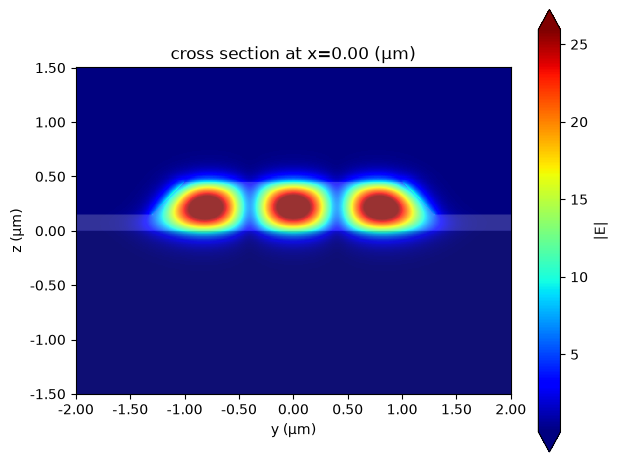

In [ ]:
# find mode
freq0 = C_0 / 0.775
mode_index = 2
mode_solver.plot_field("E", val="abs", mode_index=mode_index, f=freq0, cmap='jet')
plt.show()

# mode 0 = TE0
# mode 1 = TE1
# mode 2 = TE2
# mode 4 = TM0

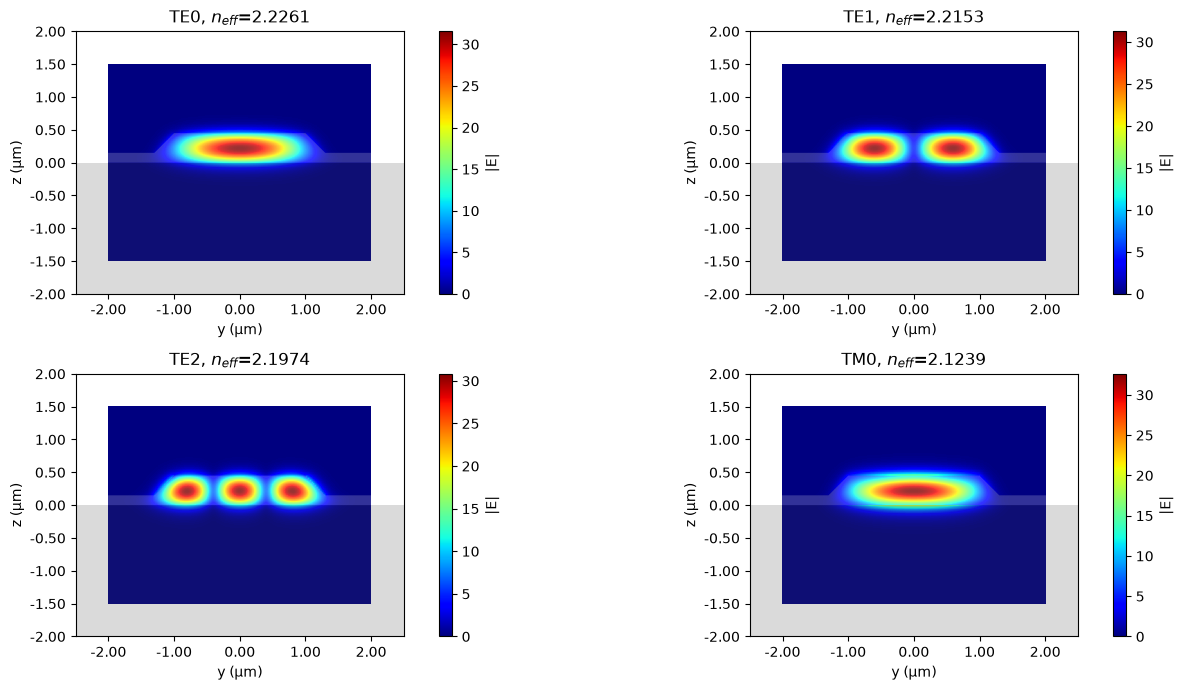

In [ ]:
# Plot all modes


# f, (ax1, ax2) = plt.subplots(2, 2, tight_layout=True, figsize=(12, 3))
freq0 = C_0 / 0.775

mode_array = [0, 1, 2, 4]  # get array of modes we want to show
mode_val = ['TE0', 'TE1', 'TE2', 'TM0']

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for m, ax in enumerate(axes.flat):
    mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=mode_array[m],
        f=freq0,
        ax=ax,
        cmap="jet",
        robust=False,
    )

    neff = np.real(
        mode_data.n_eff.isel(f=0, mode_index=mode_array[m]).values
    )

    ax.set_title(f"{mode_val[m]}, $n_{{eff}}$={neff:.4f}")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


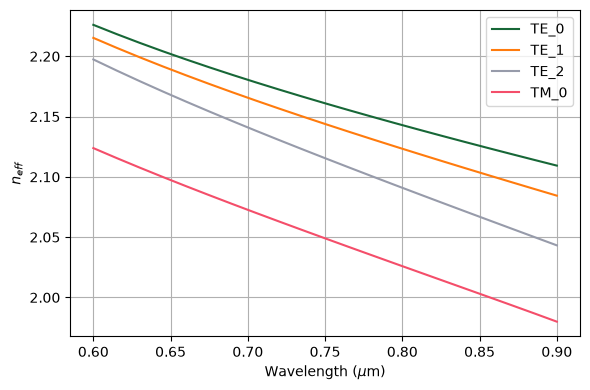

In [ ]:
n_eff = mode_data.n_eff.values

label = ['TE_0', 'TE_1', 'TE_2', 'TM_0']

fig, ax = plt.subplots(1, 1, figsize=(6, 4), tight_layout=True)
for num, mode in enumerate(mode_array):
  ax.plot(wavelengths, n_eff[:, mode], label=label[num])
# for mid in range(mode_spec.num_modes):
#     ax.plot(wavelengths, n_eff[:, mid], label=label[mid])

ax.set_xlabel(r"Wavelength ($\mu$m)")
ax.set_ylabel("$n_{eff}$")
ax.legend()
plt.grid()
plt.show()

# Figure 4 - X-Cut TLFN

11:44:23 Eastern Daylight Time WARNING: The simulation has zero size along the y
                               axis, so using a PML or absorbing boundary along 
                               that axis is incorrect. Use either 'Periodic' or 
                               'BlochBoundary' along y. Using 'Periodic'        
                               boundary by default.                             

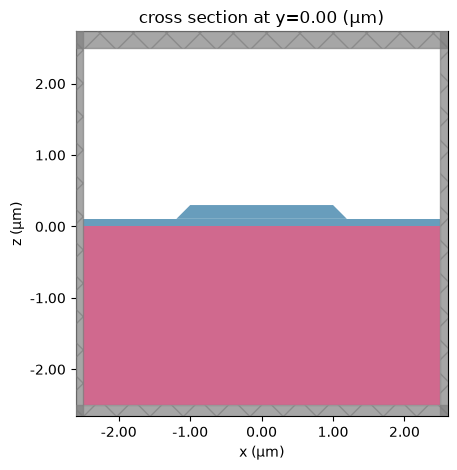

In [ ]:
# size of simulation domain
Lx, Ly, Lz = 5, 0, 5  # -- propagation in y direction, geometry in x-z
dl = 0.05

# waveguide information
h = 0.1931   # height of rib
w = 2.0      # width at top of waveguide
d = 0.3      # height of rib + film

wg_width_bottom = w + 2*h      # bottom_corner = h/tan(45deg) = h
film_height = d - h

px1 = -wg_width_bottom/2
py1 = film_height
px2 = -w/2
py2 = h + film_height
px3 = w/2
py3 = h + film_height
px4 = wg_width_bottom/2
py4 = film_height

vertices = np.array([(px1,py1), (px2,py2), (px3,py3), (px4, py4)])
tapered_wg = td.PolySlab(vertices=vertices, axis=1, slab_bounds=(-1, 1))

SiO2 = td.material_library["SiO2"]["Palik_LowLoss"]
LiNbO3 = td.material_library["LiNbO3"]["Zelmon1997"](2)

wg_permittivity = 2.1**2
film_permittivity = wg_permittivity
substrate_permittivity = 1.6**2
bg_permittivity = 1.0**2

# central frequency
wvl_um = 1.55
freq0 = C_0 / wvl_um
fwidth = freq0 / 3

# run_time in ps
run_time = 1e-12

# automatic grid specification
grid_spec = td.GridSpec.auto(min_steps_per_wvl=80, wavelength=wvl_um)

waveguide = td.Structure(
    geometry=tapered_wg,
    medium=LiNbO3,
)

film = td.Structure(
    geometry=td.Box(size=(Lx, td.inf, film_height),
                    center=[0, 0, film_height/2]),
    medium=LiNbO3,
)

substrate = td.Structure(
    geometry=td.Box(size=(Lx, td.inf, Lz/2),
                    center=[0, 0, -Lz/4]),
    medium=SiO2,
)


sim = td.Simulation(
    size=(Lx, Ly, Lz),
    grid_spec=grid_spec,
    medium=td.Medium(permittivity=bg_permittivity),
    structures=[waveguide, film, substrate],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), z=td.Boundary.pml()),
)

ax = sim.plot(y=0)
plt.show()



## Fig 3a and c-1 - TM0, TE2 @ 1550nm

In [ ]:
# wavelength sweep (1.4um to 1.7um)

plane = td.Box(center=(0, 0, 0), size=(4, 0, 3.0))
wavelengths = np.linspace(1.4, 1.7, 21)
freqs = td.C_0 / wavelengths

mode_spec = td.ModeSpec(
    num_modes=4,
    target_neff=1.6,
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=plane,
    mode_spec=mode_spec,
    freqs=freqs
)

mode_data = mode_solver.solve()
mode_data.to_dataframe()



11:45:55 Eastern Daylight Time WARNING: Mode '0' appears to undergo a           
                               discontinuous change between frequencies         
                               '207468829065743.97' and '205337300000000.0'     
                               (overlap: '0.00').                               

11:45:56 Eastern Daylight Time WARNING: Mode '3' appears to undergo a           
                               discontinuous change between frequencies         
                               '184487666461538.47' and '186206495652173.94'    
                               (overlap: '0.00').                               

wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
2.141375e+14 0                1.400  1.475763    0.0           0.0   
             1                1.400  1.638156    0.0           0.0   
             2                1.400  1.542742    0.0           0.0   
             3                1.400  1.507058    0.0           0.0   
2.118675e+14 0                1.415  1.469479    0.0           0.0   
...                             ...       ...    ...           ...   
1.779184e+14 3                1.685  1.730261    0.0           0.0   
1.763485e+14 0                1.700  1.625148    0.0           0.0   
             1                1.700  1.487039    0.0           0.0   
             2                1.700  1.463182    0.0           0.0   
             3                1.700  1.725720    0.0           0.0   

                         TE (Ex) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
2.141375e+14 0                   0.109207        0.829505        0.912287   
             1                   0.976715        0.833281        0.855199   
             2                   0.089211        0.804382        0.967126   
             3                   0.850694        0.848023        0.877931   
2.118675e+14 0                   0.108841        0.834198        0.911583   
...                                   ...             ...             ...   
1.779184e+14 3                   0.998439        0.967179        0.820341   
1.763485e+14 0                   0.989423        0.883717        0.836441   
             1                   0.942059        0.861619        0.867900   
             2                   0.016552        0.892955        0.971794   
             3                   0.998399        0.966664        0.820041   

                         mode area  
f            mode_index             
2.141375e+14 0            1.983936  
             1            1.179326  
             2            1.737347  
             3            2.296813  
2.118675e+14 0            2.062331  
...                            ...  
1.779184e+14 3            1.000373  
1.763485e+14 0            1.342557  
             1            2.444045  
             2            2.941009  
             3            1.014463  

[84 rows x 8 columns]

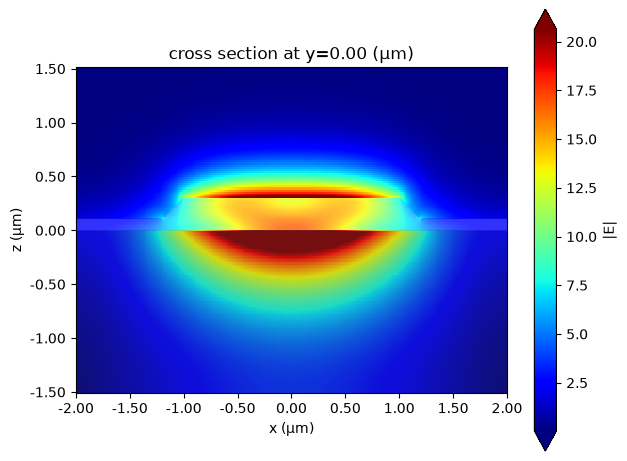

In [ ]:
# Plot modes of E field to find their specific modes
mode_index = 2

freq0 = C_0 / 1.55
mode_solver.plot_field("E", val="abs", mode_index=mode_index, f=freq0, cmap = 'jet')
plt.show()

# mode 2 = TM0
# mode 1 = TE2



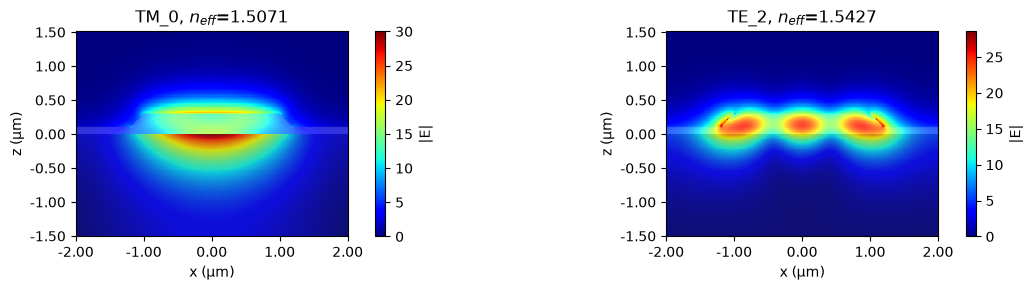

In [ ]:

f, (ax1, ax2) = plt.subplots(1, 2, tight_layout=True, figsize=(12, 3))
freq0 = C_0 / 1.55

# TM0
neff = np.real(mode_data.n_eff.isel(f=0, mode_index=3).values)
mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=2,
        f=freq0,
        ax=ax1,
        robust=False,
        cmap="jet"
    )

ax1.set_title(f"TM_0, $n_{{eff}}$={neff:.4f}")

# TE2
neff = np.real(mode_data.n_eff.isel(f=0, mode_index=2).values)
mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=1,
        f=freq0,
        ax=ax2,
        robust=False,
        cmap="jet"
    )

ax2.set_title(f"TE_2, $n_{{eff}}$={neff:.4f}")

plt.tight_layout()
plt.show()

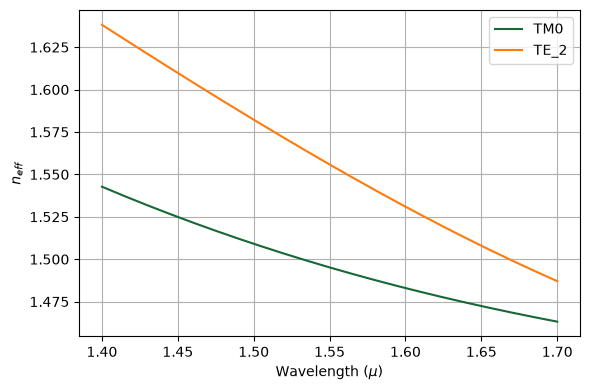

In [ ]:
n_eff = mode_data.n_eff.values

label = ['TM0', 'TE_2']

fig, ax = plt.subplots(1, 1, figsize=(6, 4), tight_layout=True)
ax.plot(wavelengths, n_eff[:, 2], label=label[0])
ax.plot(wavelengths, n_eff[:, 1], label=label[1])

ax.set_xlabel(r"Wavelength ($\mu$)")
ax.set_ylabel("$n_{eff}$")
ax.legend()
plt.grid()
plt.show()

## Fig 3b and c-2 - TE0, TE1, TE2, TM0 @ 775nm

In [ ]:
# wavelength sweep (0.6um to 0.9um)

# central frequency
wvl_um = 0.775
freq0 = C_0 / wvl_um
fwidth = freq0 / 3

# automatic grid specification
grid_spec = td.GridSpec.auto(min_steps_per_wvl=80, wavelength=wvl_um)

sim = td.Simulation(
    size=(Lx, Ly, Lz),
    grid_spec=grid_spec,
    medium=td.Medium(permittivity=bg_permittivity),
    structures=[waveguide, film, substrate],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), z=td.Boundary.pml()),
)

wavelengths = np.linspace(0.6, 0.9, 11)
freqs = td.C_0 / wavelengths

mode_spec = td.ModeSpec(
    num_modes=6,
    target_neff=2.1,
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=plane,
    mode_spec=mode_spec,
    freqs=freqs
)

mode_data = mode_solver.solve()
mode_data.to_dataframe()

11:46:02 Eastern Daylight Time WARNING: The simulation has zero size along the y
                               axis, so using a PML or absorbing boundary along 
                               that axis is incorrect. Use either 'Periodic' or 
                               'BlochBoundary' along y. Using 'Periodic'        
                               boundary by default.                             

wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
4.996541e+14 0                  0.6  2.167905    0.0           0.0   
             1                  0.6  2.155703    0.0           0.0   
             2                  0.6  2.135364    0.0           0.0   
             3                  0.6  2.106926    0.0           0.0   
             4                  0.6  2.070561    0.0           0.0   
...                             ...       ...    ...           ...   
3.331027e+14 1                  0.9  1.985346    0.0           0.0   
             2                  0.9  1.937685    0.0           0.0   
             3                  0.9  1.871389    0.0           0.0   
             4                  0.9  1.793141    0.0           0.0   
             5                  0.9  1.811061    0.0           0.0   

                         TE (Ex) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
4.996541e+14 0                   0.999896        0.996354        0.920646   
             1                   0.999549        0.985510        0.921206   
             2                   0.998818        0.967783        0.922059   
             3                   0.997272        0.943798        0.923056   
             4                   0.992943        0.914775        0.923936   
...                                   ...             ...             ...   
3.331027e+14 1                   0.998583        0.964646        0.878016   
             2                   0.995732        0.922777        0.881781   
             3                   0.985563        0.869978        0.886464   
             4                   0.661220        0.808988        0.910635   
             5                   0.006799        0.760038        0.990285   

                         mode area  
f            mode_index             
4.996541e+14 0            0.419031  
             1            0.428296  
             2            0.443508  
             3            0.464336  
             4            0.490304  
...                            ...  
3.331027e+14 1            0.549393  
             2            0.598218  
             3            0.668002  
             4            0.865209  
             5            0.771508  

[66 rows x 8 columns]

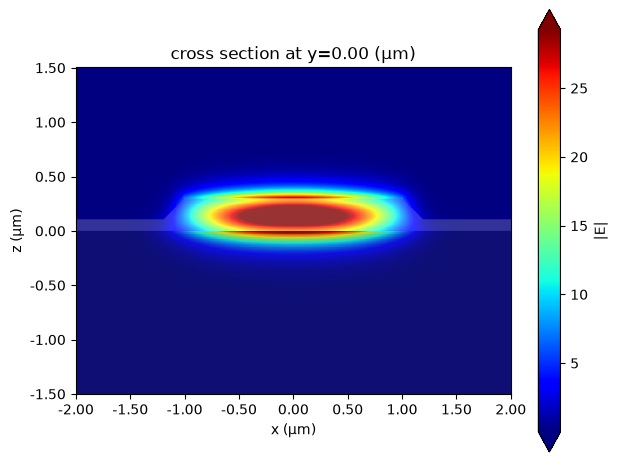

In [ ]:
# find mode
freq0 = C_0 / 0.775
mode_index = 5
mode_solver.plot_field("E", val="abs", mode_index=mode_index, f=freq0, cmap="jet")
plt.show()

# modes found by visually inspecting the mode profile
# mode 0 = TE0
# mode 1 = TE1
# mode 2 = TE2
# mode 5 = TM0

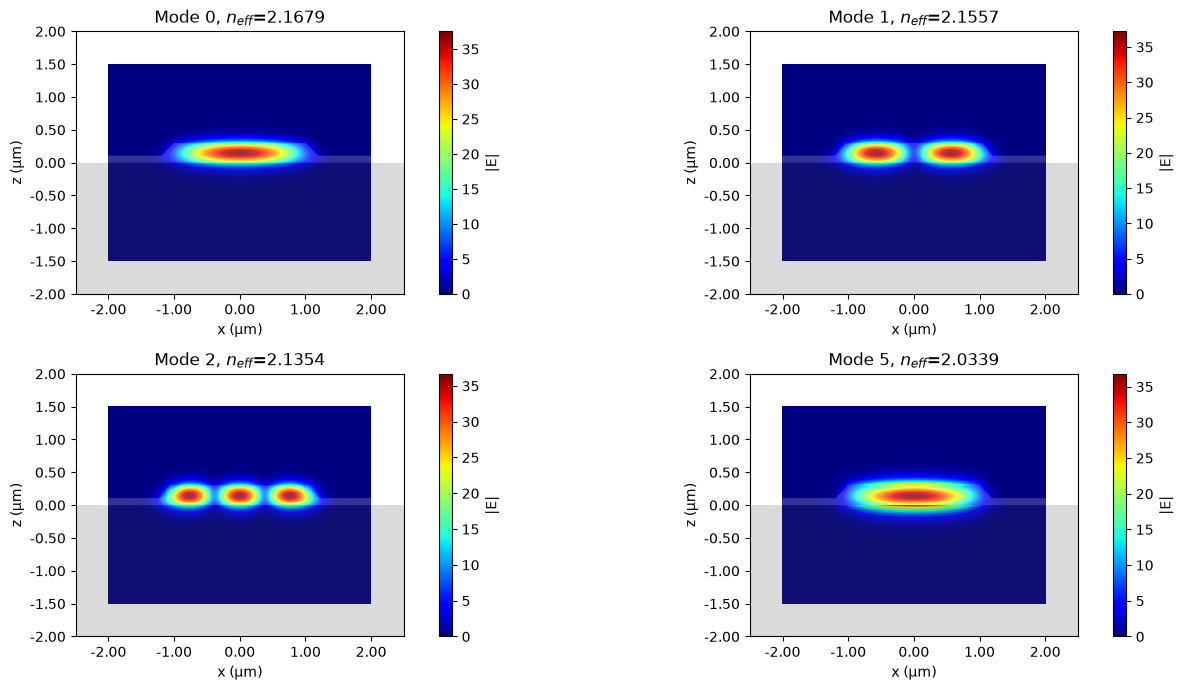

In [ ]:
# Plot all modes

# f, (ax1, ax2) = plt.subplots(2, 2, tight_layout=True, figsize=(12, 3))
freq0 = C_0 / 0.775

mode_array = [0, 1, 2, 5]  # get array of modes we want to show

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for m, ax in enumerate(axes.flat):
    mode_solver.plot_field(
        "E",
        val="abs",
        mode_index=mode_array[m],
        f=freq0,
        ax=ax,
        cmap="jet",
        robust=False,
    )

    neff = np.real(
        mode_data.n_eff.isel(f=0, mode_index=mode_array[m]).values
    )

    ax.set_title(f"Mode {mode_array[m]}, $n_{{eff}}$={neff:.4f}")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


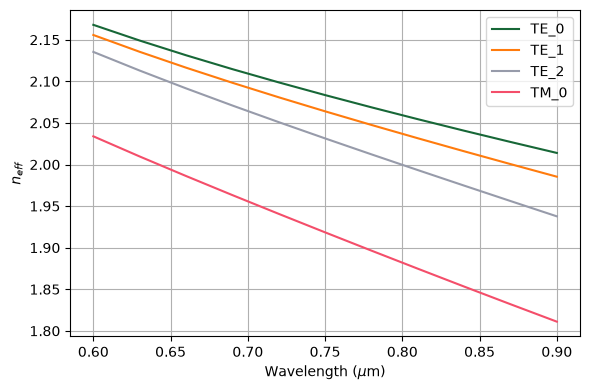

In [ ]:
n_eff = mode_data.n_eff.values

label = ['TE_0', 'TE_1', 'TE_2', 'TM_0']

fig, ax = plt.subplots(1, 1, figsize=(6, 4), tight_layout=True)
for num, mode in enumerate(mode_array):
  ax.plot(wavelengths, n_eff[:, mode], label=label[num])
# for mid in range(mode_spec.num_modes):
#     ax.plot(wavelengths, n_eff[:, mid], label=label[mid])

ax.set_xlabel(r"Wavelength ($\mu$m)")
ax.set_ylabel("$n_{eff}$")
ax.legend()
plt.grid()
plt.show()